# Experimento: CNN sobre CIFAR-10 (PyTorch)

**Estudiante:** Rodrigo Armando Oviedo Vargas  
**Código de matrícula:** 022101068E → **semilla = 68** (dos últimos dígitos)

Este notebook contiene las pruebas, el análisis exploratorio (EDA) y la visualización de muestras.
El entrenamiento completo se ejecuta con `src/train.py`.

## 0. Configuración y semilla

In [1]:
import sys
sys.path.append("..")   # para poder importar desde src/ (el notebook vive en notebooks/)

import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

from src.dataset import (SEED, DATA_DIR, CLASSES, CIFAR_MEAN, CIFAR_STD,
                         set_seed, get_transforms, load_and_split, visualize_samples)
from src.model import CNN, count_parameters, test_forward_pass

set_seed(SEED)   # torch.manual_seed(68), np.random.seed(68), ...
print("Semilla aplicada:", SEED)
print("PyTorch:", torch.__version__, "| GPU disponible:", torch.cuda.is_available())

Semilla aplicada: 68
PyTorch: 2.15.0+cpu | GPU disponible: False


## 1. Carga del dataset CIFAR-10

In [2]:
raw_train = datasets.CIFAR10(DATA_DIR, train=True, download=True)   # sin transformaciones (imágenes PIL)
raw_test = datasets.CIFAR10(DATA_DIR, train=False, download=True)

print("Imágenes de entrenamiento:", len(raw_train))
print("Imágenes de test         :", len(raw_test))
print("Clases                   :", raw_train.classes)
print("Tamaño de cada imagen    :", raw_train[0][0].size, "(ancho x alto) a color RGB")

Imágenes de entrenamiento: 50000
Imágenes de test         : 10000
Clases                   : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Tamaño de cada imagen    : (32, 32) (ancho x alto) a color RGB


## 2. EDA (análisis exploratorio)

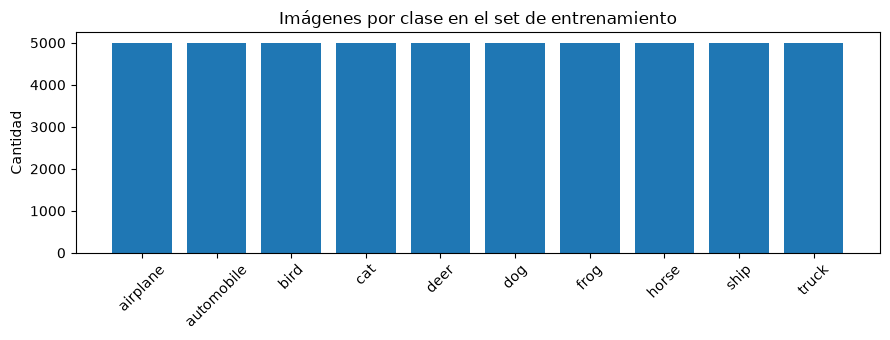

{'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


In [3]:
# 2.1 Distribución de clases (debe estar perfectamente balanceado: 5000 por clase)
counts = np.bincount(raw_train.targets)
plt.figure(figsize=(9, 3.5))
plt.bar(CLASSES, counts)
plt.title("Imágenes por clase en el set de entrenamiento")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(dict(zip(CLASSES, counts.tolist())))

In [4]:
# 2.2 Estadísticas por canal RGB (de aquí salen la media y desviación de Normalize)
data = raw_train.data / 255.0            # array (50000, 32, 32, 3) con valores en [0, 1]
print("Forma del array de imágenes:", data.shape, "-> (N, Alto, Ancho, Canales)")
print("Media por canal (R,G,B)     :", data.mean(axis=(0, 1, 2)).round(4), "| usada en Normalize:", CIFAR_MEAN)
print("Desv. estándar (R,G,B)      :", data.std(axis=(0, 1, 2)).round(4), "| usada en Normalize:", CIFAR_STD)
print("Valor mínimo / máximo       :", data.min(), "/", data.max())

Forma del array de imágenes: (50000, 32, 32, 3) -> (N, Alto, Ancho, Canales)
Media por canal (R,G,B)     : [0.4914 0.4822 0.4465] | usada en Normalize: (0.4914, 0.4822, 0.4465)
Desv. estándar (R,G,B)      : [0.247  0.2435 0.2616] | usada en Normalize: (0.247, 0.2435, 0.2616)
Valor mínimo / máximo       : 0.0 / 1.0


## 3. Visualización de muestras con su etiqueta real

[dataset] Cuadrícula guardada en: O:\Trabajos UAC\10-AB\INTELIGENCIA ARTIFICIAL - 10B\cnn-cifar10\outputs\sample_grid.png


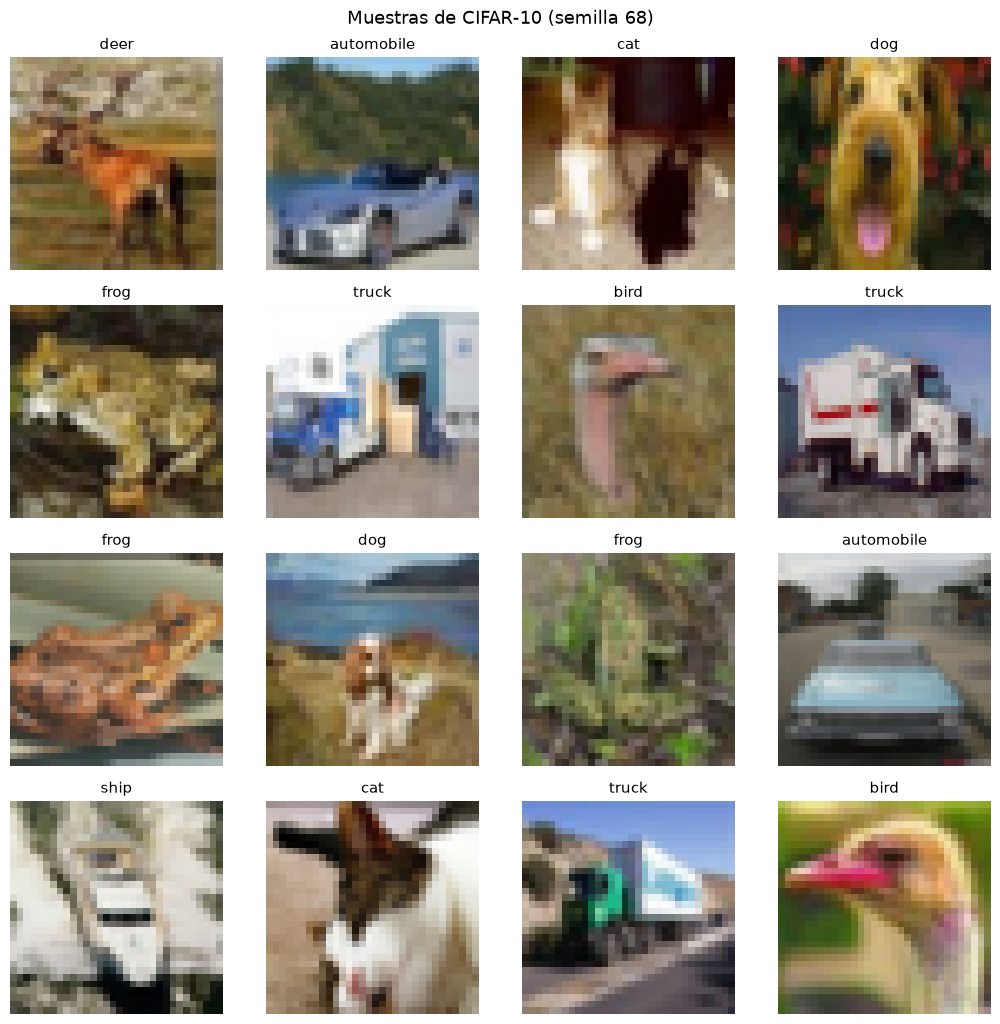

In [5]:
visualize_samples(n=16, show=True)

## 4. Pipeline de transformaciones y Data Augmentation

In [6]:
train_tf, eval_tf = get_transforms()
print("Transformaciones de ENTRENAMIENTO:\n", train_tf)
print("\nTransformaciones de VALIDACIÓN/TEST:\n", eval_tf)

Transformaciones de ENTRENAMIENTO:
 Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Transformaciones de VALIDACIÓN/TEST:
 Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


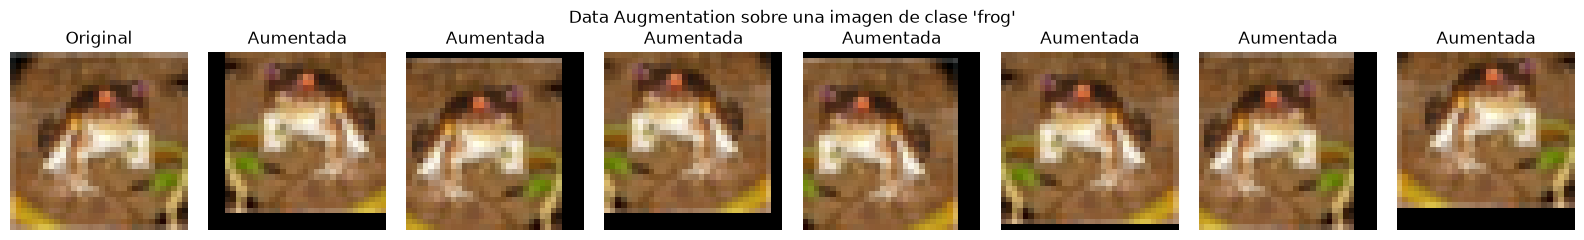

In [7]:
# Efecto del augmentation: la MISMA imagen original pasada 7 veces por RandomCrop + RandomHorizontalFlip
from torchvision import transforms
aug_only = transforms.Compose([transforms.RandomCrop(32, padding=4),
                               transforms.RandomHorizontalFlip(p=0.5)])
img, label = raw_train[0]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(img); axes[0].set_title("Original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(aug_only(img)); ax.set_title("Aumentada"); ax.axis("off")
plt.suptitle(f"Data Augmentation sobre una imagen de clase '{CLASSES[label]}'")
plt.tight_layout()
plt.show()

## 5. Partición estratificada train / validación

In [8]:
train_set, val_set, test_set = load_and_split(val_size=0.1, seed=SEED)

img_t, lab_t = train_set[0]
print("\nUna muestra individual -> imagen:", tuple(img_t.shape), "(C, H, W) | etiqueta:", lab_t)

PARTICIÓN DEL DATASET (semilla = 68)
Train      :  45000 imágenes -> tensor (N, 3, 32, 32) = (45000, 3, 32, 32)
Validación :   5000 imágenes -> tensor (N, 3, 32, 32) = (5000, 3, 32, 32)
Test       :  10000 imágenes -> tensor (N, 3, 32, 32) = (10000, 3, 32, 32)
Imágenes por clase en train      : [4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500]
Imágenes por clase en validación : [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]

Una muestra individual -> imagen: (3, 32, 32) (C, H, W) | etiqueta: 1


## 6. Arquitectura y validación de tensores 4D (forward pass)

In [9]:
model = CNN()
print(model)
print("\nParámetros entrenables:", f"{count_parameters(model):,}")

CNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)

Parámetros entrenables: 620,362


In [10]:
test_forward_pass(batch_size=8)   # imprime shapes intermedios y hace assert de la salida (8, 10)

VALIDACIÓN DE SHAPES (forward pass de prueba)
Entrada                : (8, 3, 32, 32)
Tras bloque conv 1     : (8, 32, 16, 16)
Tras bloque conv 2     : (8, 64, 8, 8)
Tras bloque conv 3     : (8, 128, 4, 4)
Tras Flatten           : (8, 2048)
Salida (logits)        : (8, 10)
--------------------------------------------------
ASERCIÓN OK: salida (8, 10) == (8, 10)
Parámetros entrenables totales: 620,362


## 7. Prueba rápida de aprendizaje (sanity check)

Si la red y el bucle de entrenamiento están bien, la pérdida debe **bajar** al entrenar repetidamente sobre un solo lote.

Lote de prueba: (64, 3, 32, 32) (64,)
Loss inicial: 2.3105  ->  Loss final: 0.2815


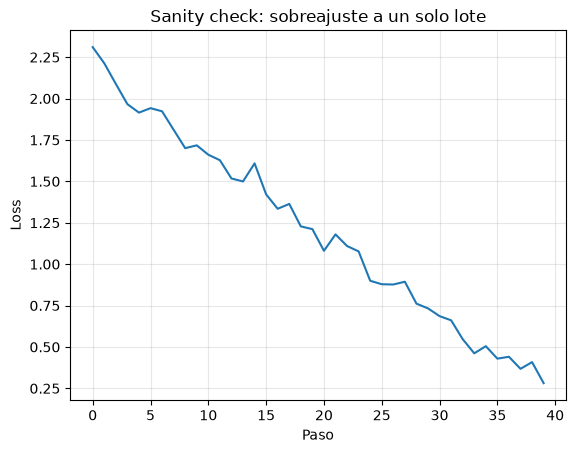

In [11]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

set_seed(SEED)
loader = DataLoader(val_set, batch_size=64, shuffle=False)
images, labels = next(iter(loader))
print("Lote de prueba:", tuple(images.shape), tuple(labels.shape))

model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

losses = []
for step in range(40):
    optimizer.zero_grad()
    loss = criterion(model(images), labels)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(f"Loss inicial: {losses[0]:.4f}  ->  Loss final: {losses[-1]:.4f}")
plt.plot(losses); plt.title("Sanity check: sobreajuste a un solo lote")
plt.xlabel("Paso"); plt.ylabel("Loss"); plt.grid(alpha=0.3); plt.show()

## 8. Entrenamiento completo

El entrenamiento por épocas, las curvas de aprendizaje y la matriz de confusión se generan con:

```bash
python src/train.py
```

Los resultados quedan en `outputs/loss_accuracy.png` y `outputs/confusion_matrix.png`.